# **Optimización de recursos utilizados en un modelo de tren urbano**
**MA4703 Control Óptimo: Teoría y Laboratorio** \
**Profesor:** Héctor Ramírez C. \
**Auxiliares:** Diego Morales, Hernán Torres \
**Ayudante:** Fraick Reyes \
**Integrantes:** Carlos Boye, Facundo Navarro

## **Contexto**
El problema a estudiar está formulado como
$$\begin{align*}\min_{s \in [0,S]} \qquad J(s)& \\ \text{s.a.} \qquad \dot{E}(s) &= u_{\text{tr}}(s) - u_{\text{b}}(s) - w(K(s)) \\ \dot{t}(s) &= \dfrac{1}{\sqrt{2K(s)}} \\ \dot{J}(s) &= u_{\text{tr}}(s) - \alpha u_{\text{b}}(s) \\ E(0) &= E_0, \, E(S) = E_S, \, t(S) - t(0) = T, \, J(0) \\ 
u_{\text{tr}}(s) &\in \left[0, \, g_{\text{tr}}(K(s))\right], \, u_{\text{b}}(s) \in \left[0, \, g_{\text{b}}(K(s))\right], \; s \in [0,S],\end{align*}$$

donde las variables utilizadas corresponden a:

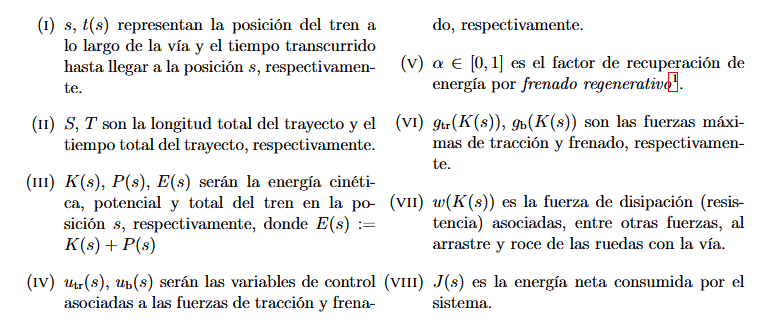

## **Programación del modelo principal**

In [ ]:
import Pkg
Pkg.add("OptimalControl")
Pkg.add("NLPModelsIpopt")
Pkg.add("Plots")

    Updating registry at `C:\Users\carlo\.julia\registries\General.toml`
     Project No packages added to or removed from `C:\Users\carlo\.julia\environments\v1.13\Project.toml`
    Manifest No packages added to or removed from `C:\Users\carlo\.julia\environments\v1.13\Manifest.toml`
     Project No packages added to or removed from `C:\Users\carlo\.julia\environments\v1.13\Project.toml`
    Manifest No packages added to or removed from `C:\Users\carlo\.julia\environments\v1.13\Manifest.toml`
     Project No packages added to or removed from `C:\Users\carlo\.julia\environments\v1.13\Project.toml`
    Manifest No packages added to or removed from `C:\Users\carlo\.julia\environments\v1.13\Manifest.toml`


▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 500)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (max_iter = 3000, tol = 1.0e-8)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     6005
Number of nonzeros in inequality constraint Jacobian.:     1503
Number of nonzeros in Lagrangian Hessian.............:     1001

Total number of variables............................:     2503
                     variables with only lower bounds:        0
                variables with lower and upper bounds:     1000
                     variables with only upper bounds:        0
Total number of equality constraints.................:     1505
Total number of inequality constraints...............:     1503
        inequality constraints with only lower bounds:      501
   inequality constraints with lower and upper bounds:        

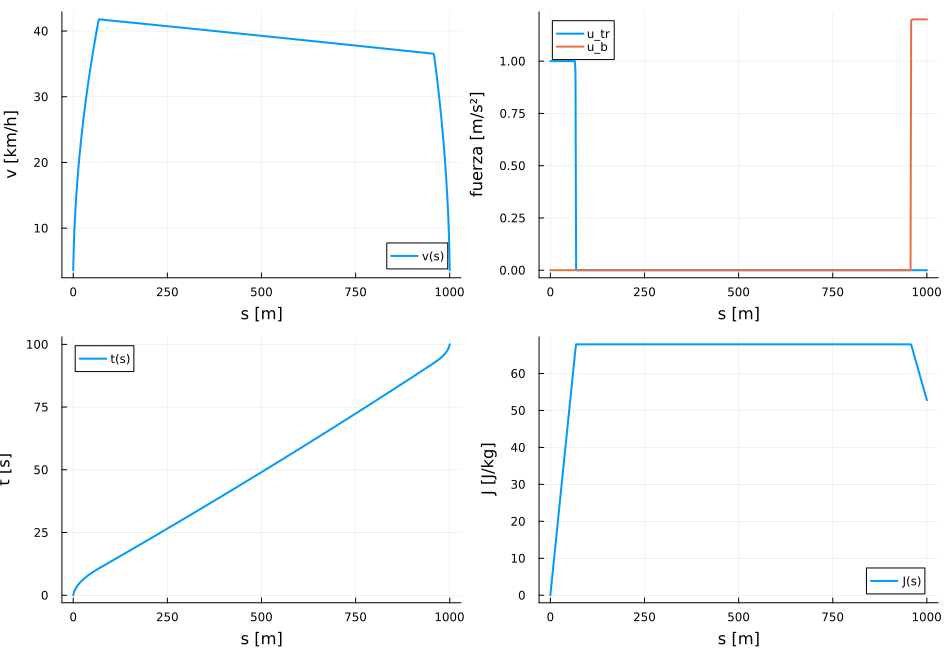

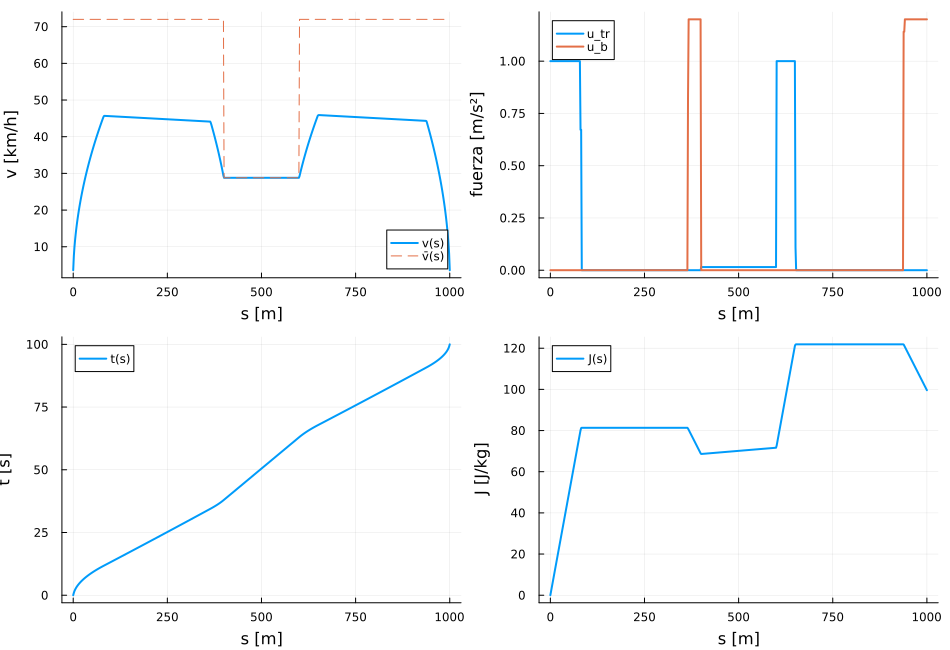

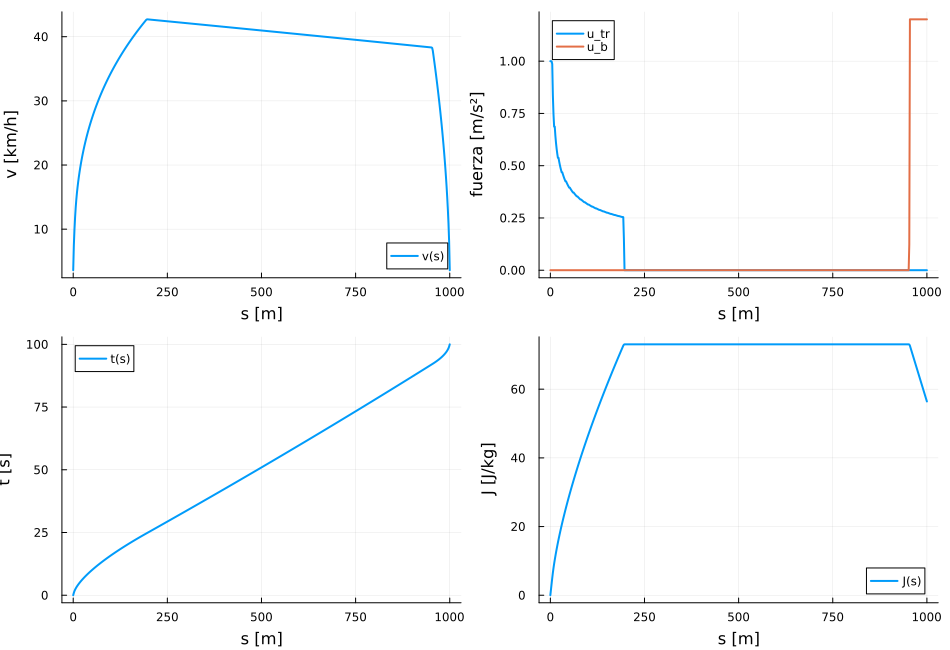

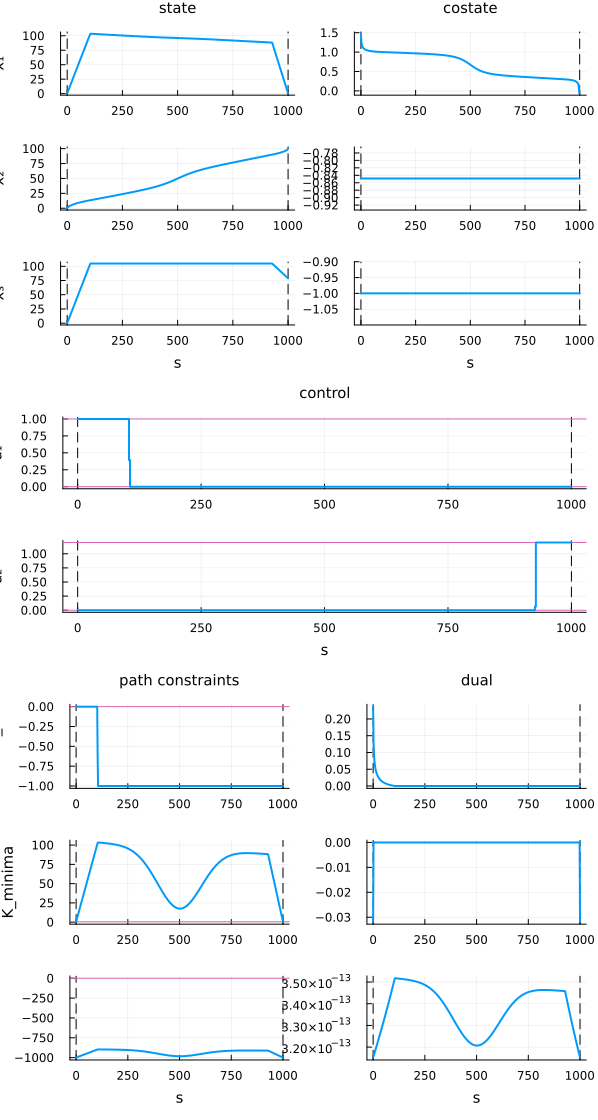

In [ ]:
using OptimalControl, NLPModelsIpopt, Plots

# Constantes a utilizar a lo largo de la programación del modelo

const S_tot = 1000 # Largo del trayecto en m
const g_grav = 9.81 # Constante de aceleración de gravedad en m/s^2
const a_d, b_d, c_d = 0.01, 5e-4, 2e-5 # Constantes asociadas a la función de resistencia de Davis por unidad de masa
const F_max = 1 # Tracción máxima en m/s^2
const gb_max = 1.2 # Frenado máximo en m/s^2

ssqrt(z) = sqrt(max(z, 1e-8)) # Hace que no hayan raíces cuadradas de números negativos para que el solver no se quede pegado.
smin(a, b; ε = 1e-3) = 0.5 * (a + b - sqrt((a - b)^2 + ε)) # Función de mínimo derivable para que, nuevamente, el solver no se quede pegado.
w(K) = a_d + b_d * ssqrt(2K) + c_d * 2K # Función de resistencia de Davis.


function tren_ocp(; α = 0.3, T = 100.0, P = s -> 0.0, Kbar = s -> 1e3, Pmax = nothing, Kmin = 0.5)
    gtr = isnothing(Pmax) ? (K -> F_max) : (K -> smin(F_max, Pmax / ssqrt(2K))) # Tracción máxima como función de K(s).
    E0 = P(0) + Kmin # Energía total inicial
    ES = P(S_tot) + Kmin # Energía total final
    ocp = @def begin
        s ∈ [0, S_tot], time
        x ∈ R^3, state
        u ∈ R^2, control

        # condiciones de borde
        x(0)       == [E0, 0, 0], (cond_inicial)
        x₁(S_tot)  == ES,         (E_final)
        x₂(S_tot)  == T,          (T_viaje)

        # cotas de control
        0 ≤ u₁(s) ≤ F_max,  (caja_traccion)
        0 ≤ u₂(s) ≤ gb_max, (caja_frenado)
        u₁(s) - gtr(x₁(s) - P(s)) ≤ 0, (traccion_max)

        # restricciones de estado:  Kmin ≤ K(s) ≤ K̄(s)
        x₁(s) - P(s) ≥ Kmin,            (K_minima)
        x₁(s) - P(s) - Kbar(s) ≤ 0,     (K_maxima)

        # dinámica
        ẋ(s) == [ u₁(s) - u₂(s) - w(x₁(s) - P(s)),
                  1 / ssqrt(2 * (x₁(s) - P(s))),
                  u₁(s) - α * u₂(s) ]

        x₃(S_tot) → min
    end
    return ocp 
end

# Función que permite hacer que el solver parta desde un punto de partida que hará que converja mejor
function puntoinicial(; T = 100.0, P = s -> 0.0)
    Kc = 0.5 * (S_tot / T)^2
    return (state   = s -> [P(s) + Kc, T * s / S_tot, w(Kc) * s], control = s -> [w(Kc) + 0.05, 0.05])
end


# Función de ploteo 
function plotear(sol; P = s -> 0.0, Kbar = nothing)
    xs, us = state(sol), control(sol)
    ss = range(0, S_tot; length = 600)
    K  = [xs(s)[1] - P(s) for s in ss]
    v  = sqrt.(max.(2 .* K, 0)) .* 3.6 # Transformación de la velocidad de m/s a km/h.
    p1 = plot(ss, v; xlabel = "s [m]", ylabel = "v [km/h]", label = "v(s)", lw = 2)
    if !isnothing(Kbar)
        plot!(p1, ss, sqrt.(2 .* Kbar.(ss)) .* 3.6; ls = :dash, label = "v̄(s)")
    end
    p2 = plot(ss, [us(s)[1] for s in ss]; label = "u_tr", lw = 2, xlabel = "s [m]", ylabel = "fuerza [m/s²]")
    plot!(p2, ss, [us(s)[2] for s in ss]; label = "u_b", lw = 2)
    p3 = plot(ss, [xs(s)[2] for s in ss]; label = "t(s)", lw = 2, xlabel = "s [m]", ylabel = "t [s]")
    p4 = plot(ss, [xs(s)[3] for s in ss]; label = "J(s)", lw = 2, xlabel = "s [m]", ylabel = "J [J/kg]")
    return plot(p1, p2, p3, p4; layout = (2, 2), size = (950, 650))
end
 
# Ejemplos de ejecución para distintas condiciones


# Primer caso: vía plana con cotas de control constantes y velocidad irrestricta
tren1 = tren_ocp(α = 0.3, T = 100)
sol1 = solve(tren1; init = puntoinicial(T = T0), grid_size = 500, tol=1e-8, max_iter = 3000)
println("J(S) óptimo = ", objective(sol1), " [J/kg]")
display(plotear(sol1))

# Segundo caso: Cota de velocidad no constantes
cota_velocidad(s) = (400 ≤ s ≤ 600) ? 0.5 * 8^2 : 0.5 * 20^2
tren2 = tren_ocp(α = 0.3, T = 100, Kbar = cota_velocidad)
sol2 = solve(tren2; init = puntoinicial(T = 100), grid_size = 500, tol = 1e-8)
display(plotear(sol2; Kbar = cota_velocidad))

# Tercer caso: Tracción limitada por la potencia g_tr(K) = min(F_max, P_max/v)
tren3 = tren_ocp(α = 0.3, T = 100, Pmax = 3, Kbar = s -> 0.5 * 20^2)
sol3 = solve(tren3; init = puntoinicial(T = 100), grid_size = 500, tol = 1e-8)
display(plotear(sol3))

# Cuarto caso: El tren atraviesa una colina de, aproximadamente, 8 metros de altura en el medio del trayecto (S ≈ 500)
colina(s) = g_grav * 8.0 * exp(-((s - 500.0) / 150.0)^2)
tren4 = tren_ocp(α = 0.3, T = 100, P = colina)
sol4 = solve(tren4; init = puntoinicial(T = 100, P = colina), grid_size = 500, tol = 1e-8)
display(plot(sol4; P = colina))

### **Variación del problema: minimizar la energía utilizada por pasajero**

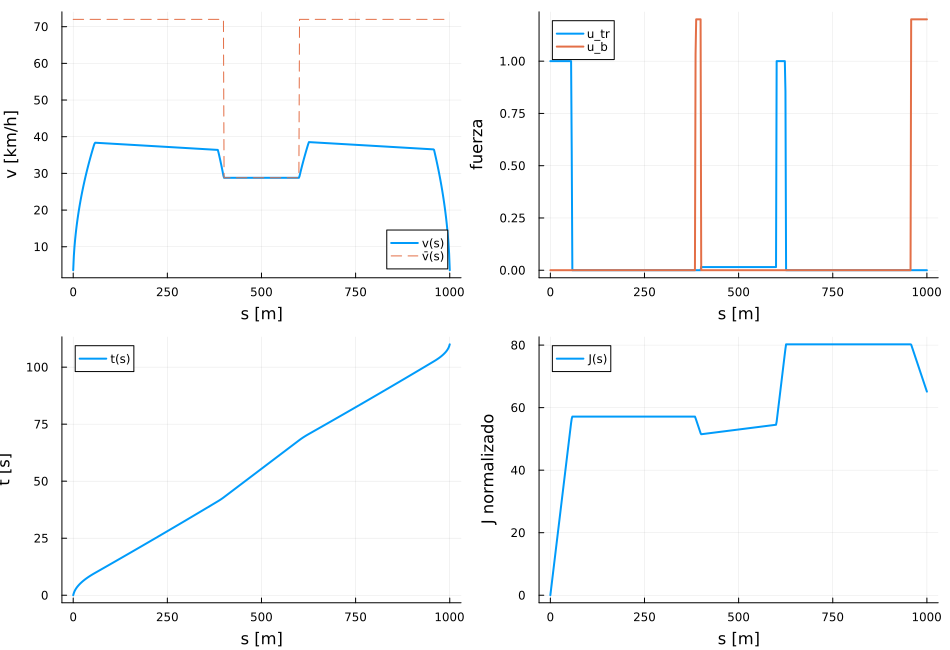

▫ This is OptimalControl 2.0.4, solving with: collocation → adnlp → ipopt (cpu)

  📦 Configuration:
   ├─ Discretizer: collocation (grid_size = 500)
   ├─ Modeler: adnlp
   └─ Solver: ipopt (tol = 1.0e-8)

▫ This is Ipopt version 3.14.19, running with linear solver MUMPS 5.9.0.

Number of nonzeros in equality constraint Jacobian...:     6005
Number of nonzeros in inequality constraint Jacobian.:     1503
Number of nonzeros in Lagrangian Hessian.............:     1001

Total number of variables............................:     2503
                     variables with only lower bounds:        0
                variables with lower and upper bounds:     1000
                     variables with only upper bounds:        0
Total number of equality constraints.................:     1505
Total number of inequality constraints...............:     1503
        inequality constraints with only lower bounds:      501
   inequality constraints with lower and upper bounds:        0
        inequal

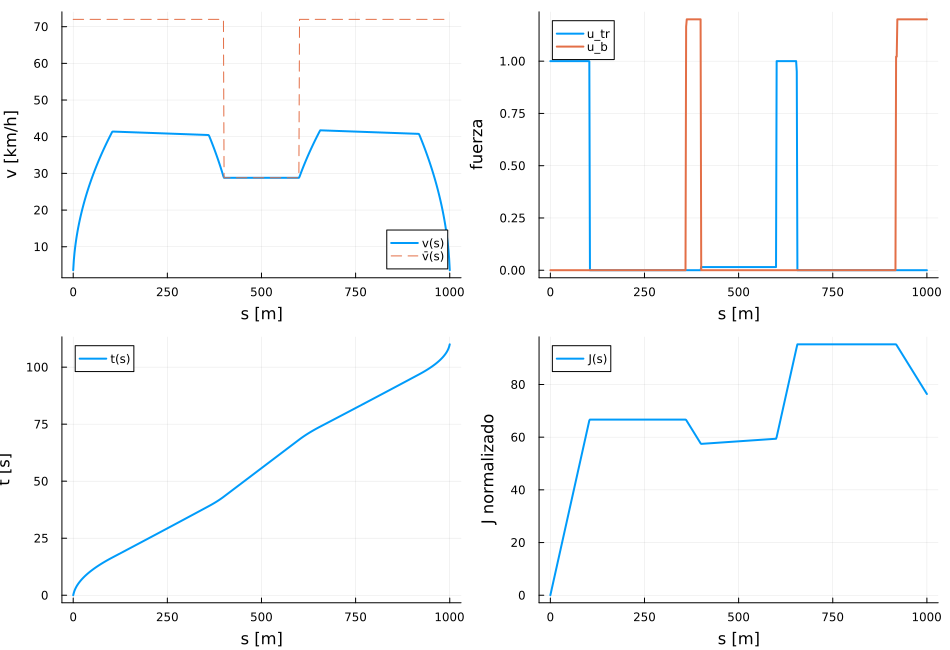

In [4]:
using OptimalControl, NLPModelsIpopt, Plots


const S_tot = 1000 
const g_grav = 9.81 
const a_d, b_d, c_d = 0.01, 5e-4, 2e-5 
const F_max = 1 
const gb_max = 1.2 
ssqrt(z) = sqrt(max(z, 1e-8)) 
smin(a, b; ε = 1e-3) = 0.5 * (a + b - sqrt((a - b)^2 + ε)) 
w(K) = a_d + b_d * ssqrt(2K) + c_d * 2K 


function tren_ocp_v2(; α = 0.3, T = 100.0, P = s -> 0.0, Kbar = s -> 1e3, Pmax = nothing, Kmin = 0.5, m = 1.0, npax = 1.0,  wm = (K, m) -> w(K / m))  
    sm = sqrt(m)                  # t' = sqrt(m) / sqrt(2K)
    Pm = s -> m * P(s)            # energía potencial: P = m g h(s)
    Kmin_m = m * Kmin             # mantiene la misma velocidad mínima
    Kbar_m = s -> m * Kbar(s)     # mantiene la misma cota de velocidad
    gtr = isnothing(Pmax) ? (K -> F_max) : (K -> smin(F_max, Pmax * sm / ssqrt(2K)))
    E0 = Pm(0) + Kmin_m          
    ES = Pm(S_tot) + Kmin_m       
    ocp = @def begin
        s ∈ [0, S_tot], time
        x ∈ R^3, state
        u ∈ R^2, control
        x(0)       == [E0, 0, 0], (cond_inicial)
        x₁(S_tot)  == ES,         (E_final)
        x₂(S_tot)  == T,          (T_viaje)
        0 ≤ u₁(s) ≤ F_max,  (caja_traccion)
        0 ≤ u₂(s) ≤ gb_max, (caja_frenado)
        u₁(s) - gtr(x₁(s) - Pm(s)) ≤ 0, (traccion_max)
        x₁(s) - Pm(s) ≥ Kmin_m,              (K_minima)
        x₁(s) - Pm(s) - Kbar_m(s) ≤ 0,       (K_maxima)
        ẋ(s) == [ u₁(s) - u₂(s) - wm(x₁(s) - Pm(s), m), sm / ssqrt(2 * (x₁(s) - Pm(s))), u₁(s) - α * u₂(s) ]
        x₃(S_tot) / npax → min
    end
    return ocp
end

# Función que permite hacer que el solver parta desde un punto de partida que hará que converja mejor
function puntoinicial(; T = 100.0, P = s -> 0.0)
    Kc = 0.5 * (S_tot / T)^2
    return (state   = s -> [P(s) + Kc, T * s / S_tot, w(Kc) * s], control = s -> [w(Kc) + 0.05, 0.05])
end

function plotear(sol; P = s -> 0.0, Kbar = nothing, m = 1.0, Jnorm = 1.0)
    xs, us = state(sol), control(sol)
    ss = range(0, S_tot; length = 600)
    K  = [xs(s)[1] - m * P(s) for s in ss]
    v  = sqrt.(max.(2 .* K ./ m, 0)) .* 3.6   # v = √(2K/m), de m/s a km/h
    p1 = plot(ss, v; xlabel = "s [m]", ylabel = "v [km/h]", label = "v(s)", lw = 2)
    if !isnothing(Kbar)
        plot!(p1, ss, sqrt.(2 .* Kbar.(ss)) .* 3.6; ls = :dash, label = "v̄(s)")
    end
    p2 = plot(ss, [us(s)[1] for s in ss]; label = "u_tr", lw = 2, xlabel = "s [m]", ylabel = "fuerza")
    plot!(p2, ss, [us(s)[2] for s in ss]; label = "u_b", lw = 2)
    p3 = plot(ss, [xs(s)[2] for s in ss]; label = "t(s)", lw = 2, xlabel = "s [m]", ylabel = "t [s]")
    p4 = plot(ss, [xs(s)[3] / Jnorm for s in ss]; label = "J(s)", lw = 2, xlabel = "s [m]", ylabel = "J normalizado")
    return plot(p1, p2, p3, p4; layout = (2, 2), size = (950, 650))
end



m_vacio = 1.0e5      # kg, tren vacío
m_pax   = 70.0       # kg por pasajero
npax = 800

# Caso 
cota_velocidad(s) = (400 ≤ s ≤ 600) ? 0.5 * 8^2 : 0.5 * 20^2

trenv1 = tren_ocp_v2(α = 0.3, T = 110, Kbar = cota_velocidad, m = 1.0, npax = 1.0)
sol1 = solve(trenv1; init = puntoinicial(T = 110), grid_size = 500, tol = 1e-8)
display(plotear(sol1; Kbar = cota_velocidad))

trenv2 = tren_ocp_v2(α = 0.3, T = 110, Kbar = cota_velocidad, m = 1 + npax * m_pax / m_vacio, npax = npax)
solv2 = solve(trenv2; init = puntoinicial(T = 110), grid_size = 500, tol = 1e-8)
display(plotear(solv2; Kbar = cota_velocidad, m = 1 + npax * m_pax / m_vacio,
                Jnorm = 1 + npax * m_pax / m_vacio))   # J por unidad de masa, comparable con el caso base

**Comentarios acerca de los resultados obtenidos.** Podemos notar lo siguiente: 
1. En el primer caso (vía plana, sin restricción de velocidad y cotas de control constantes), el control de tracción $u_{\text{tr}}(s)$ se activa en el inicio del movimiento del tren para comenzar el trayecto. Después de alcanzar, aproximadamente, $43$ km/h de velocidad, el control se desactiva y el tren avanza únicamente por la inercia del movimiento. Al acercarse el fin del trayecto $S = 1000$ m, se activa el control de frenado $u_{\text{b}}(s)$ hasta que la velocidad del tren disminuye a un valor cercano a cero (no puede ser idénticamente cero dada la programación del modelo). La energía neta $J(s)$ permanece constante (con valor $\approx 53$ J/kg) a medida que el tren avanza sin aceleración. 

2. En el segundo caso (vía plana con restricciones de velocidad no constantes y cotas de control constantes), el tren acelera nuevamente hasta alcanzar $\approx 43$ km/h de velocidad. Dado que la cota de velocidad disminuye en el intervalo $[400,600]$, el tren se ve obligado a frenar abruptamente antes de alcanzar los $400$ m para mantenerse en el borde de la restricción. Para cumplir, efectivamente, la restricción, el tren acelera levemente (activación de la fuerza de tracción $u_{\text{tr}}(s)$). Una vez que la restricción de velocidad vuelve al valor anterior, el tren vuelve a acelerar mediante tracción hasta alcanzar los $\approx 43$ km/h de velocidad y seguir el trayecto hasta frenar antes de llegar a los $1000$ m. 

3. En el tercer caso (vía plana con restricciones sobre el control de tracción), el tren comienza acelerando con tracción al máximo hasta que se llega a $v = 3$ m/s (que es donde se activa la restricción de tracción). Después de alcanzar los $3$ km/h, la tracción del tren decrece convexamente hasta que éste alcanza los $\approx 43$ km/h. El comportamiento restante es equivalente al del primer caso. 

4. En el cuarto caso (vía con una colina de $\approx 8$ m de altura centrada en $s = 500$ m, sin restricciones de velocidad y con cotas de control constantes), el tren acelera con tracción máxima durante los primeros $\approx 105$ m, hasta alcanzar una velocidad cercana a $52$ km/h, mayor que en el primer caso. Luego el control de tracción se desactiva y el tren avanza por inercia durante casi todo el trayecto, incluyendo la subida de la colina: al subir, la energía cinética se transforma en energía potencial y la velocidad disminuye hasta $\approx 22$ km/h en la cima ($s = 500$ m); al bajar, esa energía potencial se recupera como energía cinética y el tren vuelve a acelerar sin usar tracción. Cerca de $s \approx 925$ m se activa el frenado máximo hasta que el tren se detiene. Notar que la energía total $E(s) = K(s) + P(s)$ disminuye casi linealmente (solo por la disipación $w(K)$) aunque la velocidad varíe mucho, de modo que la colina se aprecia en $K(s) = E(s) - P(s)$ y no en $E(s)$. 

## **Programación del modelo de Eugene Khmelnitsky**
En el paper de E. Khmelnitsky, *On an Optimal Control Problem of Train Operation*, el doctor en ingeniería industrial israelí programa una versión directa del modelo: para cada variación de éste (con pendientes arbitrarias y restricciones de velocidad variables), se encuentra la forma de la solución óptima mediante el principio del máximo de Pontryagin. En este caso, problema para encontrar la energía neta óptima se reduce a encontrar numéricamente los puntos de conmutación $\psi_T$. Esto último se realiza mediante un método de *bisección*: una especie de *búsqueda binaria* continua para dar con el tiempo de conmutación correcto (fundamentado en la proposición de la imagen).

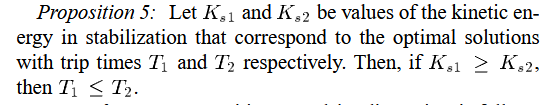

El teorema 1 del paper de Khmelnitsky, por otra parte, asegura que, si existe solución, ésta es única:

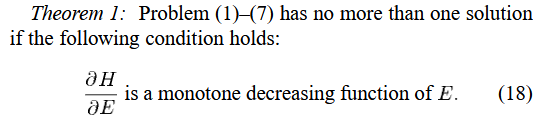

In [9]:
import Pkg
Pkg.add("StaticArrays")

    Updating registry at `C:\Users\carlo\.julia\registries\General.toml`
    Updating `C:\Users\carlo\.julia\environments\v1.13\Project.toml`
⌃ [90137ffa] + StaticArrays v1.9.24
    Manifest No packages added to or removed from `C:\Users\carlo\.julia\environments\v1.13\Manifest.toml`


  it   1  ψ_T =  -6.059914  K_s = 1222.7168  T = 70.343425  J = 128.67760  [nocruise]
  it   2  ψ_T =  -3.030227  K_s =  742.2700  T = 79.219475  J = 90.76643  [nocruise]
  it   3  ψ_T =  -1.515384  K_s =  446.8181  T = 92.133657  J = 63.09167  [nocruise]
  it   4  ψ_T =  -0.757962  K_s =  266.3014  T = 109.974403  J = 43.92486  [nocruise]
  it   5  ψ_T =  -1.136673  K_s =  360.9208  T = 98.884989  J = 54.22807  [nocruise]
  it   6  ψ_T =  -0.947317  K_s =  314.9507  T = 103.633810  J = 49.29940  [nocruise]
  it   7  ψ_T =  -1.041995  K_s =  338.2318  T = 101.104260  J = 51.81272  [nocruise]
  it   8  ψ_T =  -1.089334  K_s =  349.6463  T = 99.959894  J = 53.03195  [nocruise]
  it   9  ψ_T =  -1.065664  K_s =  343.9570  T = 100.522935  J = 52.42530  [nocruise]
  it  10  ψ_T =  -1.077499  K_s =  346.8060  T = 100.239189  J = 52.72936  [nocruise]
  it  11  ψ_T =  -1.083416  K_s =  348.2273  T = 100.098992  J = 52.88083  [nocruise]
  it  12  ψ_T =  -1.086375  K_s =  348.9370  T = 100.02930

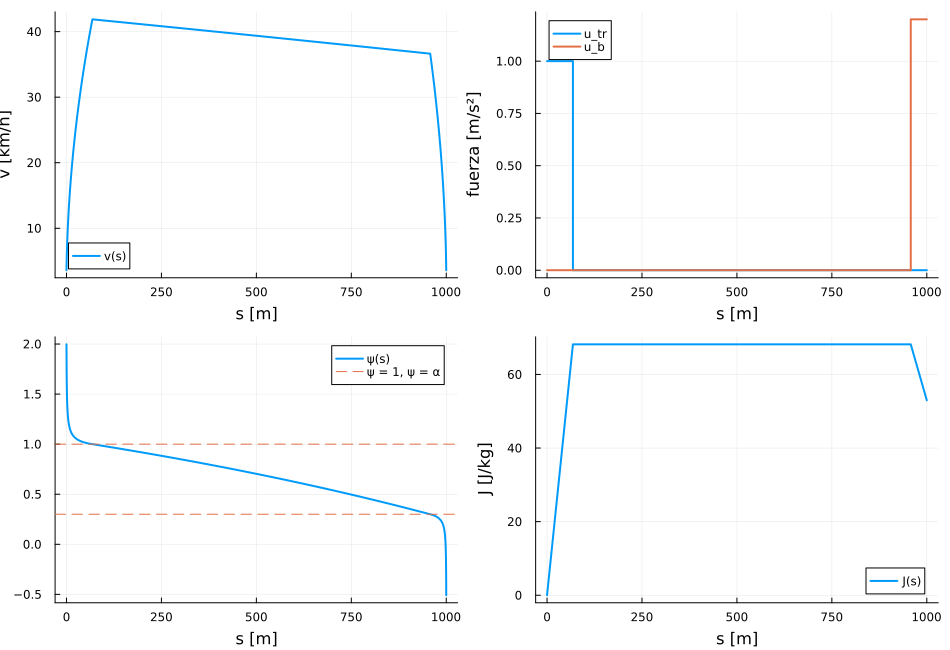

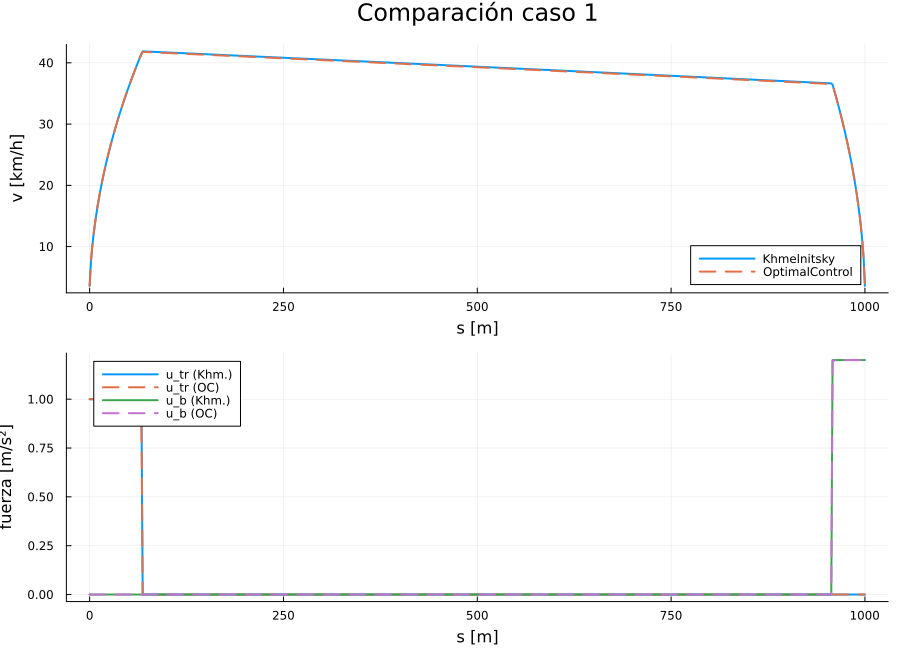

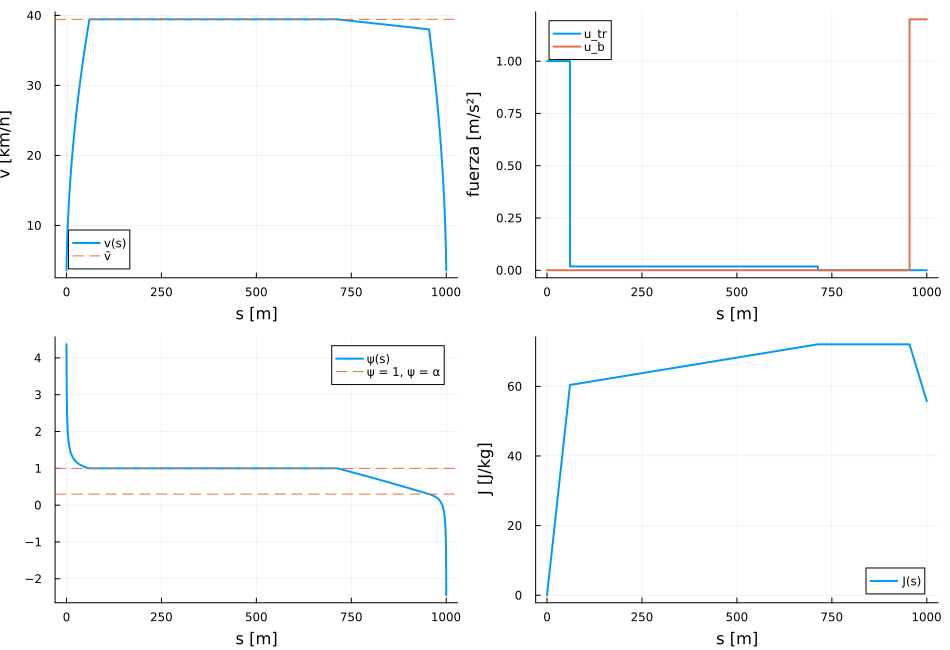

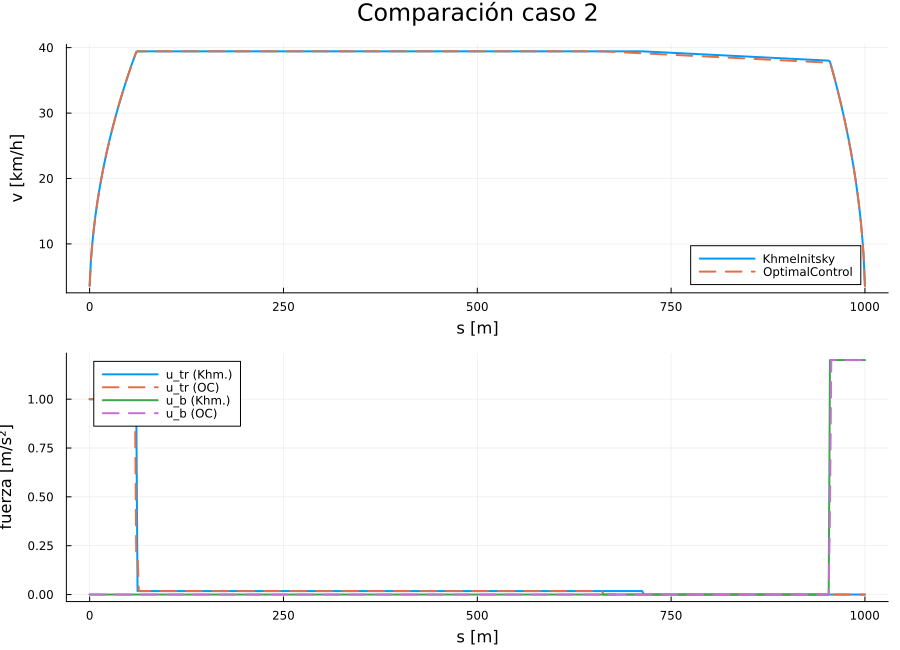

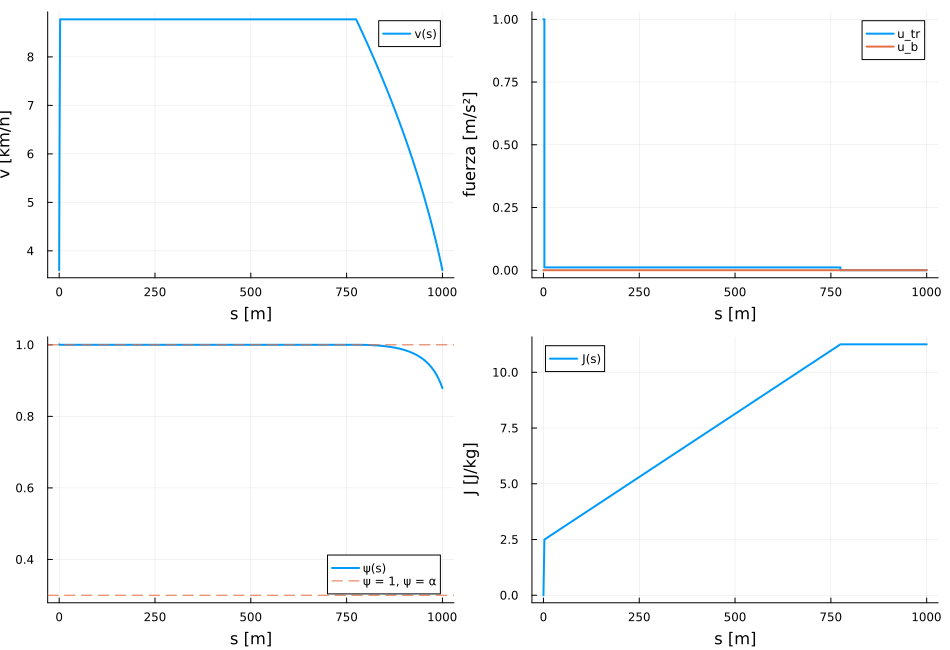

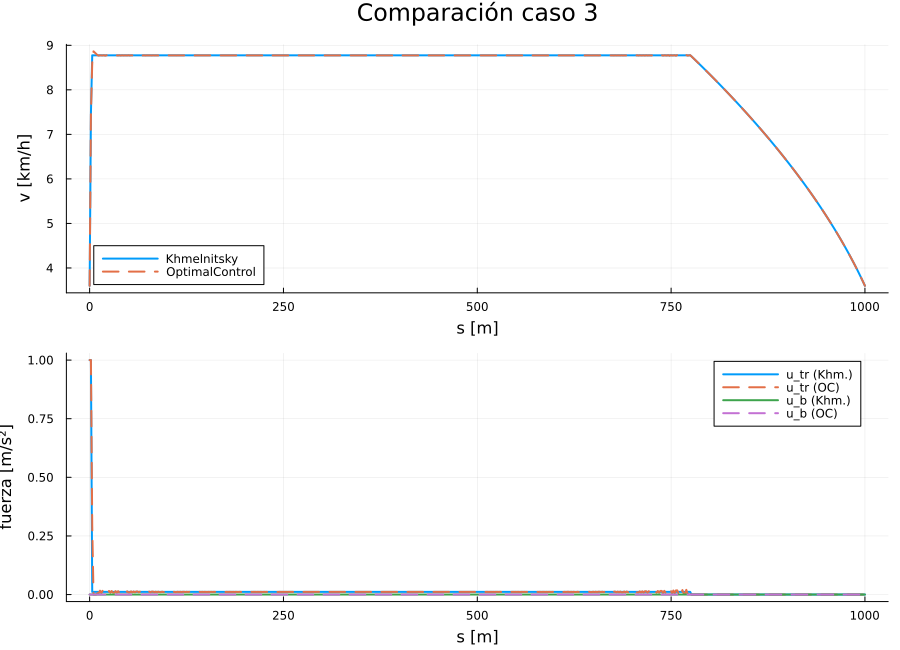

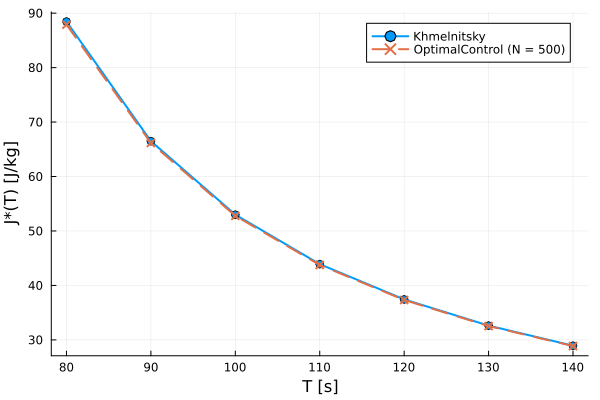

In [ ]:
using StaticArrays
using Plots
using Printf

# Definimos las variables que ocupará el modelo a lo largo del código

Base.@kwdef struct TrainParams
    S::Float64    = 1000.0   # largo del trayecto [m]
    T::Float64    = 100.0    # tiempo de viaje [s]
    α::Float64    = 0.3      # constante 0 ≤ α < 1
    K0::Float64   = 0.5      # energía cinética inicial
    KS::Float64   = 0.5      # energía cinética final
    Kbar::Float64 = Inf      # cota de velocidad K̄ 
    Ftr::Float64  = 1.0      # tracción máxima
    Fb::Float64   = 1.2      # frenado máximo
    a::Float64    = 0.01     # constantes asociadas a la función de resistencia de Davis
    b::Float64    = 5e-4
    c::Float64    = 2e-5
end

# Función de resistencia de Davis por unidad de masa
davis_khm(p, K) = p.a + p.b * sqrt(2K) + 2p.c * K     

# Función R que permite calcular la energía cinética durante el proceso de "estabilización" del tren
R_khm(p, K) = p.b * K / sqrt(2) + 2p.c * K^1.5          

# Función que calcula el K tal que R(K) = r mediante el método de bisección 
function kh_Rinv(p, r)
    lo, hi = 0.0, 1.0
    while R_khm(p, hi) < r
        hi *= 2
    end
    for _ in 1:200
        m = (lo + hi) / 2
        R_khm(p, m) < r ? (lo = m) : (hi = m)
    end
    return (lo + hi) / 2
end

# Función que modela el lado derecho de la dinámica del tren fuera del régimen de "estabilización" (ver imagen debajo del bloque de código)
function dinamica17_khm(p::TrainParams, mode::Symbol, Rs)
    return function (K, y)
        ψ = y[1]
        dψds = (ψ * R_khm(p, K) - Rs) / K^1.5
        if mode === :trac
            net = p.Ftr - davis_khm(p, K);  Js = p.Ftr
        elseif mode === :coast
            net = -davis_khm(p, K);         Js = 0.0
        else
            net = -p.Fb - davis_khm(p, K);  Js = -p.α * p.Fb
        end
        ds = 1 / net
        return SVector(dψds * ds, ds, ds / sqrt(2K), Js * ds)
    end
end

# Función que, mediante el método de Runge-Kutta de orden 4, permite aproximar una solución de la dinámica anterior

function rungekutta_khm(f, K, y, h)
    k1 = f(K, y)
    k2 = f(K + h/2, y + (h/2) * k1)
    k3 = f(K + h/2, y + (h/2) * k2)
    k4 = f(K + h,   y + h * k3)
    return y + (h/6) * (k1 + 2*k2 + 2*k3 + k4)
end

# Construye un tramo completo de la trayectoria del tren: permite obtener la evolución de ψ, s, t y J 
function construirtramo_khm(f, Ka, Kb, y0, n; event = nothing)
    h = (Kb - Ka) / n
    K = Ka
    y = SVector{4,Float64}(y0)
    Ks = Float64[K]
    Ys = SVector{4,Float64}[y]
    hit = false
    g0 = event === nothing ? 0.0 : event(y)
    for _ in 1:n
        y1 = rungekutta_khm(f, K, y, h)
        if event !== nothing
            g1 = event(y1)
            if g0 > 0 && g1 <= 0
                lo, hi = 0.0, 1.0
                for _ in 1:60
                    m = (lo + hi) / 2
                    event(rungekutta_khm(f, K, y, m * h)) > 0 ? (lo = m) : (hi = m)
                end
                θ = (lo + hi) / 2
                y1 = rungekutta_khm(f, K, y, θ * h)
                push!(Ks, K + θ * h)
                push!(Ys, y1)
                hit = true
                break
            end
            g0 = g1
        end
        K += h
        y = y1
        push!(Ks, K)
        push!(Ys, y)
    end
    return Ks, Ys, hit
end

# Función que calcula la salida (modo de viaje producido después de salir del modo crucero) desde un punto con ψ = 1
function kh_exit(p::TrainParams, Ka, ystart, Rs, n)
    arcs = Any[]
    Ka <= p.KS && return (arcs, SVector{4,Float64}(ystart))
    Kc, Yc, hit = construirtramo_khm(dinamica17_khm(p, :coast, Rs), Ka, p.KS, ystart, n; event = y -> y[1] - p.α)
    push!(arcs, (:coast, Kc, Yc))
    y = Yc[end]
    if hit
        Kb, Yb, _ = construirtramo_khm(dinamica17_khm(p, :brake, Rs), Kc[end], p.KS, y, n)
        push!(arcs, (:brake, Kb, Yb))
        y = Yb[end]
    end
    return arcs, y
end

# Estructura que permite evaluar T(ψ_T)
struct EvaluarTrayectoriaKhm
    Ks::Float64; Kc::Float64; ψT::Float64
    kind::Symbol                    
    T::Float64; J::Float64; dc::Float64; y0::Float64
    entry_K::Vector{Float64}
    entry_Y::Vector{SVector{4,Float64}}
    entry_off::NTuple{3,Float64}    
    exit_arcs::Vector{Any}
end

# Función que evalúa las trayectorias (paso 2 a 6 en el paper)
function evaluartrayectoria_khm(p::TrainParams, Ks::Real, n::Int)
    Rs = R_khm(p, Ks)                    # ψ_T = -2^{3/2} R(K_s)   (ec. 12)
    Kc = min(Ks, p.Kbar)                # nivel de crucero
    p.Ftr - davis_khm(p, Kc) <= 0 && return nothing
    ψT = -2^1.5 * Rs
    z  = SVector(1.0, 0.0, 0.0, 0.0)
    Ke, Ye, _ = construirtramo_khm(dinamica17_khm(p, :trac, Rs), Kc, p.K0, z, n)
    d_in, t_in, J_in = -Ye[end][2], -Ye[end][3], -Ye[end][4]
    arcs_out, yo = kh_exit(p, Kc, z, Rs, n)
    dc = p.S - d_in - yo[2]           
    if dc >= 0
        T = t_in + yo[3] + dc / sqrt(2 * Kc)
        J = J_in + yo[4] + davis_khm(p, Kc) * dc
        return KhTrial(Ks, Kc, ψT, :cruise, T, J, dc, NaN, Ke, Ye, (d_in, t_in, J_in), arcs_out)
    end
    rhs_t = dinamica17_khm(p, :trac, Rs)
    function shoot(y0ψ)
        Kt, Yt, hit = construirtramo_khm(rhs_t, p.K0, Kc, SVector(y0ψ, 0.0, 0.0, 0.0), n; event = y -> y[1] - 1.0)
        hit || return nothing           
        yt = Yt[end]
        ao, yo2 = kh_exit(p, Kt[end], SVector(1.0, yt[2], yt[3], yt[4]), Rs, n)
        return (Kt, Yt, ao, yo2)
    end
    G(y0ψ) = (o = shoot(y0ψ); o === nothing ? Inf : o[4][2] - p.S)
    lo, hi = 1.0 + 1e-9, 2.0
    G(lo) > 0 && return nothing
    while G(hi) < 0
        hi = 1 + 2 * (hi - 1)
        hi > 1e6 && return nothing
    end
    for _ in 1:60
        m = (lo + hi) / 2
        G(m) < 0 ? (lo = m) : (hi = m)
    end
    Kt, Yt, ao, yo2 = shoot(lo)         
    return KhTrial(Ks, Kc, ψT, :nocruise, yo2[3], yo2[4], 0.0, lo, Kt, Yt, (0.0, 0.0, 0.0), ao)
end

# Función que guarda cada información importante de la trayectoria en cada posición: pos. s, K, ψ, t, J, u_tr, u_b y tipo de viaje (tracción, coasting, etc.)
function armarperfil_khm(p::TrainParams, r::KhTrial)
    s = Float64[]; K = Float64[]; ψ = Float64[]; t = Float64[]; J = Float64[]
    utr = Float64[]; ub = Float64[]
    regimes = Tuple{Symbol,Float64,Float64}[]
    label = Dict(:trac => :traccion, :coast => :coasting, :brake => :frenado)
    function push_arc!(name, Ks_, Ys_, off; rev = false)
        idx = rev ? (length(Ks_):-1:1) : (1:length(Ks_))
        n0 = length(s) + 1
        for i in idx
            y = Ys_[i]
            push!(s, y[2] + off[1]); push!(K, Ks_[i]); push!(ψ, y[1])
            push!(t, y[3] + off[2]); push!(J, y[4] + off[3])
            if name === :trac
                push!(utr, p.Ftr); push!(ub, 0.0)
            elseif name === :coast
                push!(utr, 0.0);   push!(ub, 0.0)
            else
                push!(utr, 0.0);   push!(ub, p.Fb)
            end
        end
        push!(regimes, (label[name], s[n0], s[end]))
    end
    off = (0.0, 0.0, 0.0)
    if r.kind === :cruise
        push_arc!(:trac, r.entry_K, r.entry_Y, r.entry_off; rev = true)
        d_in, t_in, J_in = r.entry_off
        tc = r.dc / sqrt(2 * r.Kc)
        Jc = davis_khm(p, r.Kc) * r.dc
        for (si, ti, Ji) in ((d_in, t_in, J_in), (d_in + r.dc, t_in + tc, J_in + Jc))
            push!(s, si); push!(K, r.Kc); push!(ψ, 1.0); push!(t, ti); push!(J, Ji)
            push!(utr, davis_khm(p, r.Kc)); push!(ub, 0.0)
        end
        push!(regimes, (:crucero, d_in, d_in + r.dc))
        off = (d_in + r.dc, t_in + tc, J_in + Jc)
    else
        push_arc!(:trac, r.entry_K, r.entry_Y, off)
    end
    for (name, Ks_, Ys_) in r.exit_arcs
        push_arc!(name, Ks_, Ys_, off)
    end
    return (s = s, K = K, ψ = ψ, t = t, J = J, utr = utr, ub = ub, regimes = regimes)
end

# Algoritmo final de Khmelnitsky (paso 1 y 7 del paper)
function khmelnitsky(p::TrainParams; n::Int = 1000, tol = 1e-6, maxit::Int = 100, verbose::Bool = true)
    @assert 0 ≤ p.α < 1 "0 ≤ α < 1"
    @assert max(p.K0, p.KS) < p.Kbar "K0, KS < K̄"
    Klo = max(p.K0, p.KS) * (1 + 1e-6)    
    Khi = 2000.0                           
    ψhi = -2^1.5 * R_khm(p, Klo)            
    ψlo = -2^1.5 * R_khm(p, Khi)            #
    rhi = evaluartrayectoria_khm(p, Khi, n)
    (rhi === nothing || rhi.T > p.T) && error("T = $(p.T) s es menor que el tiempo mínimo alcanzable con estas cotas")
    rlo = evaluartrayectoria_khm(p, Klo, n)
    (rlo !== nothing && rlo.T < p.T) && error("T = $(p.T) s es demasiado grande: el tren iría más lento que K0/KS")
    lo, hi = ψlo, ψhi
    best = nothing
    for it in 1:maxit
        m = (lo + hi) / 2
        r = evaluartrayectoria_khm(p, kh_Rinv(p, -m / 2^1.5), n)      # paso 1 del paper 
        if r === nothing || r.T > p.T                   # paso 7 del paper 
            hi = m
        else
            lo = m
        end
        r === nothing && continue
        best = r
        verbose && @printf("  it %3d  ψ_T = %10.6f  K_s = %9.4f  T = %.6f  J = %.5f  [%s]\n", it, m, r.Ks, r.T, r.J, r.kind)
        abs(r.T - p.T) < tol && break
    end
    best === nothing && error("la bisección no encontró un ψ_T válido")
    r = best
    abs(r.T - p.T) > 1e-3 && @warn "no se alcanzó T con la precisión pedida" r.T p.T
    pr = armarperfil_khm(p, r)
    res = (p = p, trial = r, profile = pr, ψT = r.ψT, Ks = r.Ks, T = r.T, J = r.J, kind = r.kind, regimes = pr.regimes)
    return res
end

# Plotear
function plotear_khm(res)
    p, pr = res.p, res.profile
    p1 = plot(pr.s, sqrt.(2 .* pr.K) .* 3.6; lw = 2, label = "v(s)",
              xlabel = "s [m]", ylabel = "v [km/h]")
    isfinite(p.Kbar) && hline!(p1, [sqrt(2 * p.Kbar) * 3.6]; ls = :dash, label = "v̄")
    p2 = plot(pr.s, pr.utr; lw = 2, label = "u_tr", xlabel = "s [m]", ylabel = "fuerza [m/s²]")
    plot!(p2, pr.s, pr.ub; lw = 2, label = "u_b")
    p3 = plot(pr.s, pr.ψ; lw = 2, label = "ψ(s)", xlabel = "s [m]")
    hline!(p3, [1.0, p.α]; ls = :dash, label = "ψ = 1, ψ = α")
    p4 = plot(pr.s, pr.J; lw = 2, label = "J(s)", xlabel = "s [m]", ylabel = "J [J/kg]")
    return plot(p1, p2, p3, p4; layout = (2, 2), size = (950, 650))
end



# Funciones que servirán para comparar resultados con la solución de OptimalControl obtenida

function at_khm(sv, xv, s0)
    s0 <= sv[1]   && return xv[1]
    s0 >= sv[end] && return xv[end]
    i = searchsortedlast(sv, s0)
    sv[i+1] == sv[i] && return xv[i]
    return xv[i] + (xv[i+1] - xv[i]) * (s0 - sv[i]) / (sv[i+1] - sv[i])
end


function compararsol(res, sol; titulo = "")
    p, pr = res.p, res.profile
    xs, us = state(sol), control(sol)
    ss = range(0, p.S; length = 600)
    vk = [sqrt(2 * at_khm(pr.s, pr.K, s)) for s in ss]
    vo = [sqrt(2 * xs(s)[1]) for s in ss]
    isempty(titulo) || println("=== ", titulo, " ===")
    @printf("J Khmelnitsky = %.5f   J OptimalControl = %.5f   diferencia relativa = %.2e\n", res.J, objective(sol), abs(res.J - objective(sol)) / res.J)
    @printf("máx |Δv| = %.3f m/s   (v_máx = %.2f m/s)\n", maximum(abs.(vk .- vo)), maximum(vk))
    p1 = plot(ss, vk .* 3.6; lw = 2, label = "Khmelnitsky", xlabel = "s [m]", ylabel = "v [km/h]")
    plot!(p1, ss, vo .* 3.6; lw = 2, ls = :dash, label = "OptimalControl")
    p2 = plot(ss, [at_khm(pr.s, pr.utr, s) for s in ss]; lw = 2, label = "u_tr (Khm.)", xlabel = "s [m]", ylabel = "fuerza [m/s²]")
    plot!(p2, ss, [us(s)[1] for s in ss]; lw = 2, ls = :dash, label = "u_tr (OC)")
    plot!(p2, ss, [at_khm(pr.s, pr.ub, s) for s in ss]; lw = 2, label = "u_b (Khm.)")
    plot!(p2, ss, [us(s)[2] for s in ss]; lw = 2, ls = :dash, label = "u_b (OC)")
    kw = isempty(titulo) ? (;) : (; plot_title = titulo)
    return plot(p1, p2; layout = (2, 1), size = (900, 650), kw...)
end

# OJO: Al estar el modelo restringido a cotas de velocidad constantes, los casos a comparar no serán los mismos que los vistos en OptimalControl

# Primer caso: vía plana con cotas de control constantes y velocidad irrestricta
T0   = 100
khm1 = khmelnitsky(TrainParams(T = float(T0), α = 0.3))
display(plotear_khm(khm1))
display(compararsol(khm1, sol1;  titulo = "Comparación caso 1"))

# Segundo caso (versión con cota de velocidad constante): K̄ = 60 
khm2   = khmelnitsky(TrainParams(T = 100.0, α = 0.3, Kbar = 60.0))
display(plotear_khm(khm2))
tren2c = tren_ocp(α = 0.3, T = 100, Kbar = s -> 60.0)
sol2c  = solve(tren2c; init = puntoinicial(T = 100), grid_size = 500, tol = 1e-8)
display(compararsol(khm2, sol2c; titulo = "Comparación caso 2"))

# Tercer caso: viaje lento (T grande) 
khm3   = khmelnitsky(TrainParams(T = 450.0, α = 0.3))
display(plotear_khm(khm3))
tren3c = tren_ocp(α = 0.3, T = 450)
sol3c  = solve(tren3c; init = puntoinicial(T = 450), grid_size = 500, tol = 1e-8)
display(compararsol(khm3, sol3c; titulo = "Comparación caso 3"))

# Comparación entre Khmelnitsky y OptimalControl: ψ_T = dJ*/dT* 
Ts      = 80.0:10.0:140.0
Js_khm  = [khmelnitsky(TrainParams(T = T, α = 0.3); verbose = false).J for T in Ts]
Js_ocp  = [objective(solve(tren_ocp(α = 0.3, T = T); init = puntoinicial(T = T), grid_size = 500, tol = 1e-8, display = false)) for T in Ts]
pareto = plot(Ts, Js_khm; marker = :o, lw = 2, xlabel = "T [s]", ylabel = "J*(T) [J/kg]", label = "Khmelnitsky")
plot!(pareto, Ts, Js_ocp; marker = :x, lw = 2, ls = :dash, label = "OptimalControl (N = 500)")
display(pareto)

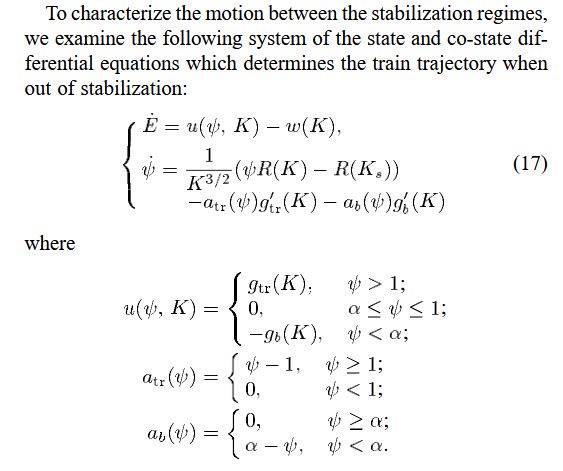

In [ ]:
# === Comparación caso 1 ===
#= J Khmelnitsky = 52.98829   J OptimalControl = 52.77451   diferencia relativa = 4.03e-03
máx |Δv| = 0.027 m/s   (v_máx = 11.63 m/s) =#

#= === Comparación caso 2 ===
J Khmelnitsky = 55.69982   J OptimalControl = 55.05004   diferencia relativa = 1.17e-02
máx |Δv| = 0.085 m/s   (v_máx = 10.95 m/s) =#

#= === Comparación caso 3 ===
J Khmelnitsky = 11.25483   J OptimalControl = 11.25457   diferencia relativa = 2.33e-05
máx |Δv| = 0.047 m/s   (v_máx = 2.44 m/s) =#
